--ИМПОРТ БИБЛИОТЕК--

In [3]:
import numpy as np
import matplotlib.pyplot as plt

--РЕАЛИЗАЦИЯ КЛАССА--

In [13]:
class PolynomialRegression:
    def __init__(self, degree=1):
        self.degree = degree
        self.coef = None
        self.best_degree = None
        self.history = []

    def _design(self, X, degree):
        X = np.asarray(X, dtype=float).ravel()
        return np.column_stack([X ** p for p in range(degree + 1)])

    def fit(self, X, y):
        Phi = self._design(X, self.degree)
        y = np.asarray(y, dtype=float).ravel()
        self.coef, *_ = np.linalg.lstsq(Phi, y, rcond=None)
        return self

    def predict(self, X):
        return self._design(X, self.degree) @ self.coef

    @staticmethod
    def _kfold(n, k, seed=42):
        idx = np.arange(n)
        np.random.default_rng(seed).shuffle(idx)
        folds = np.array_split(idx, k)
        for i in range(k):
            test = folds[i]
            train = np.concatenate([folds[j] for j in range(k) if j != i])
            yield train, test

    def fit_auto(self, X, y, max_degree=10, criterion="cv", k_folds=5, seed=42):
        X = np.asarray(X, dtype=float).ravel()
        y = np.asarray(y, dtype=float).ravel()
        n = len(y)
        self.history.clear()
        best_score, best_degree = np.inf, 0

        for d in range(max_degree + 1):
            cv = []
            for tr, te in self._kfold(n, k_folds, seed):
                m = PolynomialRegression(d).fit(X[tr], y[tr])
                cv.append(np.mean((y[te] - m.predict(X[te])) ** 2))
            cv_mse = float(np.mean(cv))

            full = PolynomialRegression(d).fit(X, y)
            met = self._metrics(y, full.predict(X), d)
            ss_res = met["MSE"] * n
            k_params = d + 1
            aic = n * np.log(ss_res / n + 1e-12) + 2 * k_params
            bic = n * np.log(ss_res / n + 1e-12) + k_params * np.log(n)

            self.history.append(
                {"degree": d, "cv_mse": cv_mse, "AIC": aic, "BIC": bic, **met}
            )

            score = {"cv": cv_mse, "aic": aic, "bic": bic}[criterion]
            if score < best_score:
                best_score, best_degree = score, d

        self.degree = self.best_degree = best_degree
        return self.fit(X, y)

    @staticmethod
    def _metrics(y_true, y_pred, k):
        y_true = np.asarray(y_true, dtype=float).ravel()
        y_pred = np.asarray(y_pred, dtype=float).ravel()
        res = y_true - y_pred
        mse = float(np.mean(res ** 2))
        ss_res = float(np.sum(res ** 2))
        ss_tot = float(np.sum((y_true - y_true.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0.0

        return {
            "MSE": mse,
            "RMSE": float(np.sqrt(mse)),
            "MAE": float(np.mean(np.abs(res))),
            "R2": r2,
        }

    def score(self, X, y):
        return self._metrics(y, self.predict(X), self.degree)


--ВИЗУАЛИЗАЦИЯ--

degree: 2
coef: [ 1.042 -2.016  0.489]
MSE: 0.22919910149614262
RMSE: 0.4787474297540851
MAE: 0.38686237253784883
R2: 0.9839764776170539


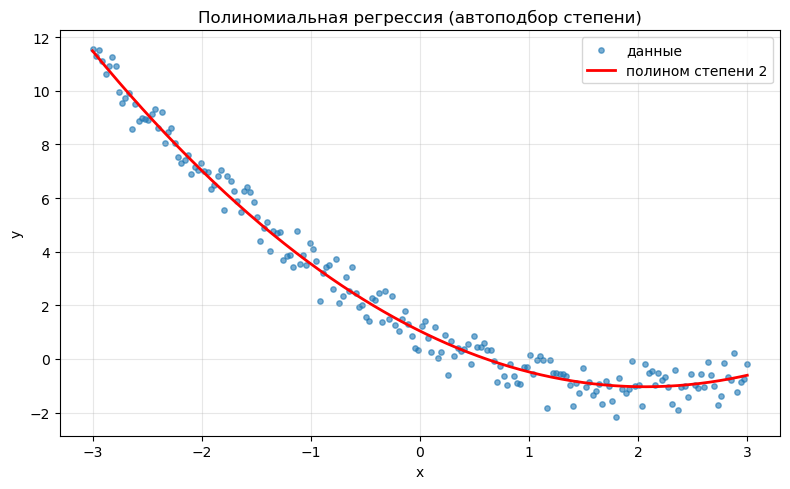

In [16]:
rng = np.random.default_rng(0)
X = np.linspace(-3, 3, 200)
y = 1 - 2 * X + 0.5 * X ** 2 + rng.normal(0, 0.5, X.shape)

m = PolynomialRegression().fit_auto(X, y, max_degree=8, criterion="cv")
print("degree:", m.best_degree)
print("coef:", np.round(m.coef, 3))
for k, v in m.score(X, y).items():
    print(f"{k}: {v}")

X_plot = np.linspace(X.min(), X.max(), 500)
y_plot = m.predict(X_plot)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, s=15, alpha=0.6, label="данные")
plt.plot(X_plot, y_plot, "r-", lw=2,
         label=f"полином степени {m.best_degree}")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Полиномиальная регрессия (автоподбор степени)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()